#Markov Decision Process
Assume that we have the following grid world:

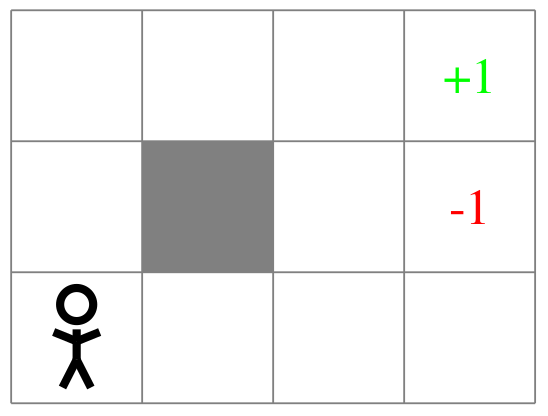

The goal of the agent whose position is at the bottom left corner is to maximize the expected future reward.

The top right (reward +1) and the middle right cell (reward -1) are terminal states.

There are four different actions the agent can choose, namely go up, down, left and right.

However, there is a chance that the agent will result in a wrong grid cell by accident.

If the action is going up, there is a chance of 0.8 that the agent moves up, a chance of 0.1 that he moves left and a chance of 0.1 that he moves right.

All other actions behave accordingly. If the agent would bounce on a wall it stays at the current position. Note that the agent cannot move through the grayed-out grid cell.
Assume a gamma value of  $\gamma=0.9$.

Assume that the following utility values are given:

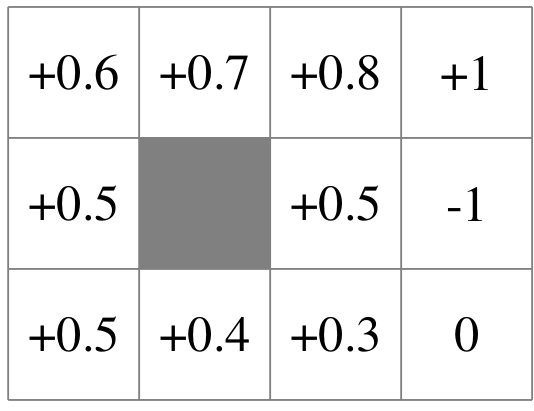

##Environment Definition:

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
class MDP: #MDP:Markov Decission Process
  "4:up, 1:right, -1:left, -4:down"
  _transitions = np.array([
    [[4,0.8],[-1,0.1],[1,0.1]],#up
    [[1,0.8],[-4,0.1],[4,0.1]],#right
    [[-1,0.8],[-4,0.1],[4,0.1]],#left
    [[-4,0.8],[-1,0.1],[1,0.1]]#down
  ])

  def __init__(self, gamma=0.9):
    self.reward = np.zeros(3*4)
    self.reward[-1] = 1 #celda final vale +1
    self.reward[5] = -10 #celda gris
    self.reward[4] = -1 #celda roja vale -1
    self.gamma = gamma

  def rewards(self, state):
    return self.reward[state]

  def _bounces(self,state,s):
    return np.sum(np.abs(np.array(np.where(np.arange(12).reshape((3,4)) == state)) -
                         np.array(np.where(np.arange(12).reshape((3,4)) == s)))) > 1

  def transition(self, state, action):
    if state == 7 or state == 11:
      return np.zeros((0,2))
    trans = MDP._transitions[action].copy()
    trans = trans.T
    trans[0,:] += state
    trans = trans.T
    for i, (s,prob) in enumerate(trans):
      if s < 0 or s >= 12 or s == 5 or self._bounces(state,s):
        trans[i,0] = state
    return trans

In [ ]:
utilities = np.array([0.5,0.4,0.3,0,
                      0.5,-10,0.5,-1,
                      0.6,0.7,0.8,1])

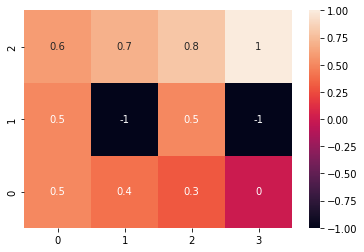

In [ ]:
def show_utilities(ut):
  plt.figure()
  reshaped = ut.reshape((3,4))
  reshaped[1,1] = -1
  ax = sns.heatmap(reshaped, annot=True)
  ax.invert_yaxis()

show_utilities(utilities)

In [ ]:
mdp = MDP()

##Value Iteration
Implement the value iteration algorithm.

In [ ]:
def q(mdp, state, action, utilities):
  trans = mdp.transition(state,action)
  return np.sum(utilities[trans.T[0].astype(int)] * trans.T[1])

def value_iteration(mdp, utilities):
  ut_new = np.zeros(len(utilities)) #inicializar en 0
  n = 0
  delta = np.inf
  while delta > 1e-10:
    for state in range(len(utilities)):
      #U'[s] = R(s) + gama * max_a sum_s' P(s'|s,a)*U[s']
      ut_new[state] = mdp.rewards(state) + mdp.gamma * np.max([q(mdp,state,a,utilities) for a in range(4)])
    delta = np.max(np.abs(utilities - ut_new))
    utilities = ut_new.copy()
    n += 1
  print(n)
  return utilities

31


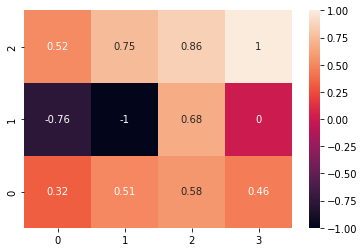

In [ ]:
optimal = value_iteration(mdp, utilities)
#print(optimal)
show_utilities(optimal)

In [ ]:
def extract_policy(position, qtable):
  qtable = qtable.reshape((3,4))
  policy = []
  path = [position]
  #print(position)
  while position[0] != 2 or position[1] != 3:
    neighborhood = []
    if position[0] > 0:
      neighborhood += [('down',qtable[position[0] - 1,position[1]])]
    if position[0] < 2:
      neighborhood += [('up',qtable[position[0] + 1,position[1]])]
    if position[1] > 0:
      neighborhood += [('left',qtable[position[0],position[1] - 1])]
    if position[1] < 3:
      neighborhood += [('right',qtable[position[0],position[1] + 1])]
    #print(neighborhood)
    action = [n[0] for n in neighborhood if n[1] == max([n1[1] for n1 in neighborhood])][0]
    #print(action)
    if action == 'down':
      position = (position[0] - 1, position[1])
    if action == 'up':
      position = (position[0] + 1, position[1])
    if action == 'right':
      position = (position[0], position[1] + 1)
    if action == 'left':
      position = (position[0], position[1] - 1)
    #print(position)
    policy += [action]
    path += [position]
  return policy,path

['right', 'right', 'up', 'up', 'right']
[(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3)]


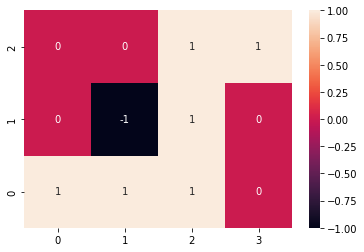

In [ ]:
policy,path = extract_policy((0,0),optimal)
print(policy)
print(path)

opt = np.zeros(12).reshape((3,4))

for p in path:
  opt[p[0],p[1]] = 1
show_utilities(opt)

#Policy Evaluation
Implement a policy evaluation step in order evaluate the utility values of the improved policy.

In [ ]:
def policy_improvement(mdp,policy):
  policy = np.zeros(len(utilities))
  for state in range(len(utilities)):
    policy[state] = np.argmax([q(mdp,state,a,utilities) for a in range(4)])
  return policy

In [ ]:
def policy_evaluation(mdp,policy):
  states = len(policy)
  reward = [mdp.rewards(s) for s in range(states)]
  prob_matrix = np.eye(states)
  for state in range(states):
    trans = mdp.transition(state, policy[state])
    for i, (s,prob) in enumerate(trans):
      prob_matrix[state,int(s)] -= mdp.gamma * prob
  return np.linalg.solve(prob_matrix,reward)

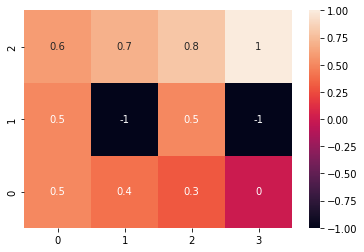

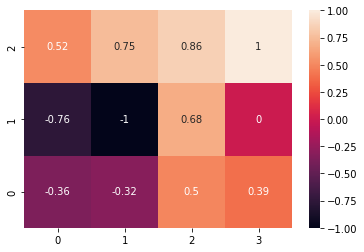

In [ ]:
show_utilities(utilities)
show_utilities(policy_evaluation(mdp, policy_improvement(mdp,utilities).astype(int)))

In [ ]:
def policy_iteration(mdp,utilities):
  policy = np.zeros(len(utilities),dtype=int)
  while True:
    utilities = policy_evaluation(mdp,policy)
    policy_next = policy_improvement(mdp, utilities).astype(int)
    if np.sum(policy_next != policy) == 0:
      break
    policy = policy_next
  return policy

[2 2 0 2 0 0 0 0 1 1 1 0]
[-0.36098646 -0.31696372  0.4957689   0.39225671 -0.76208254 -9.46480092
  0.6791563   0.          0.52096156  0.75369784  0.8583781   1.        ]


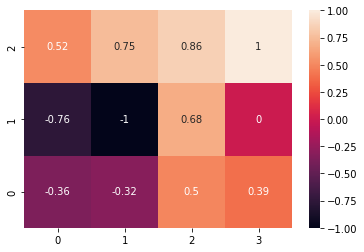

In [ ]:
policy = policy_iteration(mdp, utilities)
print(policy)
optimal_ut = policy_evaluation(mdp, policy)
print(optimal_ut)
show_utilities(optimal_ut)

In [ ]:
extract_policy((0,0), optimal_ut)

(['right', 'right', 'up', 'up', 'right'],
 [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3)])